# 발표용 그림 생성 — `09_presentation_figures`

> 15분 발표(`outputs/발표_15분_marp.md`)에 들어가는 그림을 만든다. **기존 결과 CSV만 시각화**한다
> — 재인코딩·재토큰화·회귀 재실행 없음(가드레일). 배치(headless) 버전은
> `analysis/09_presentation_figures.py`, 이 노트북은 **그림 1개 = 셀 1개**로 띄워 두어
> *figsize·폭·여백을 바꿔 재실행 → inline 확인 → png/pdf 저장* 을 반복하기 쉽게 한 것이다.
>
> **출력**: `reports/presentation_figures/{figNN}.png` + `.pdf` (DPI 200, `bbox_inches='tight'`,
> `pad_inches=0.25`로 잘림 여유). **폰트**: Noto Sans KR→Apple SD Gothic Neo→AppleGothic 폴백,
> `axes.unicode_minus=False`(− 글리프 깨짐 방지), `≈/≤` 등은 한글로 대체.
>
> | 셀 | 그림 | 들어갈 슬라이드 | 데이터 |
> |---|---|---|---|
> | fig01 | 설계 흐름도 | 슬4 | (도식) |
> | fig02 | 규모가 먼저(43%) | 슬5 | `07d_a1_hierarchical_r2.csv` |
> | fig03 | 분량 착시 | A4 | `07d_a4_length_myth.csv` |
> | fig04 | 생존 매트릭스(메타발견) | 슬6 | `07d_a3_fullcontrol_coef.csv`·`07d_a3_meta_survival.csv` |
> | fig05 | DRIVER vs BOILER | 슬7 | `08_h2_keyword_density_corr.csv`·`08_h2_top_vs_bottom.csv` |
> | fig06 | TF-IDF vs dense 개념도 | 슬8 | `08_h4_dimension_separation.csv`·`07d_a7_g_convergence.csv` |
> | fig07 | 공시량 대비 등급 사분면 | 슬10 | `07d_synthesis_table.csv`(+`_resid`) |
> | fig08 | 약신호 forest CI | A5/슬11 | `07d_a6_signal_ci.csv` |
>
> **잘림이 보이면**: 해당 셀의 `figsize`를 키우거나, 가장자리 주석의 좌표(예 `fig.text(..., -0.02, ...)`)를
> 안쪽으로 옮기거나, 위 `save_fig`의 `pad_inches`를 늘려 재실행한다.

## 0. 셋업 — 폰트 · 팔레트 · 저장 헬퍼
아래 헬퍼는 편집 가능하다. `save_fig`는 figure를 **닫지 않아** inline으로 표시되고,
`pad_inches`로 가장자리 잘림 여유를 둔다. (배치 `.py`의 헬퍼와 동일하되 inline용으로 닫지 않음.)

In [1]:
%matplotlib inline
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle, FancyBboxPatch

ROOT = "/Users/home1/esg-dart-project"
DP   = f"{ROOT}/data/processed"
OUT  = f"{ROOT}/reports/presentation_figures"
os.makedirs(OUT, exist_ok=True)
sys.path.insert(0, f"{ROOT}/analysis")
from synth_lib import _resid, SIZE_Z, LEN_Z, SECTOR_DUMMIES, INTEG_GRADE   # fig07 잔차 재현용

def set_korean_font():
    cands = ["Noto Sans KR", "Apple SD Gothic Neo", "AppleGothic", "NanumGothic", "Malgun Gothic"]
    avail = {f.name for f in font_manager.fontManager.ttflist}
    chosen = next((c for c in cands if c in avail), "AppleGothic")
    plt.rcParams["font.family"] = chosen
    plt.rcParams["axes.unicode_minus"] = False   # − 글리프 깨짐(□) 방지
    return chosen
FONT = set_korean_font(); print("font:", FONT)

# §10.5 팔레트(상수)
P = {
    "dominant": "#34495E",   # 규모/1차 지배
    "control":  "#95A5A6",   # 기타 통제
    "text_weak":"#BDC3C7",   # 텍스트 신호 약
    "signal":   "#2563EB",   # 생존/핵심 신호
    "driver":   "#2A9D8F",   # DRIVER/선택적 실질
    "boiler":   "#C9A227",   # BOILER/의무 형식
    "nonrobust":"#F4A259",   # 비강건
    "null":     "#E3E6E8",   # 비유의/null
    "neg":      "#E15759",   # 음(−) 관계 강조
    "ink":      "#1f2937",
    "muted":    "#6b7280",
}
BODY = (12.0, 6.75)   # 16:9 본문 그림 기본 figsize
DPI = 200

def save_fig(fig, name):
    """png+pdf 저장. figure를 닫지 않아 inline 표시됨. pad_inches로 잘림 여유."""
    for ext in ("png", "pdf"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=DPI, bbox_inches="tight",
                    pad_inches=0.25, facecolor="white")
    print("saved", name, "→", OUT)

def _despine(ax, keep=("left", "bottom")):
    for s in ("top", "right", "left", "bottom"):
        ax.spines[s].set_visible(s in keep)
    ax.tick_params(length=0)

font: Apple SD Gothic Neo


### 슬4 — 연구 설계 흐름도
`fig01_design_flow` · 박스+화살표 도식(데이터 없음, 수작업 배치). 칸 위치는 `box(x,y,w,h,...)` 좌표로 조정.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig01_design_flow.png·.pdf` 저장**.

saved fig01_design_flow → /Users/home1/esg-dart-project/reports/presentation_figures


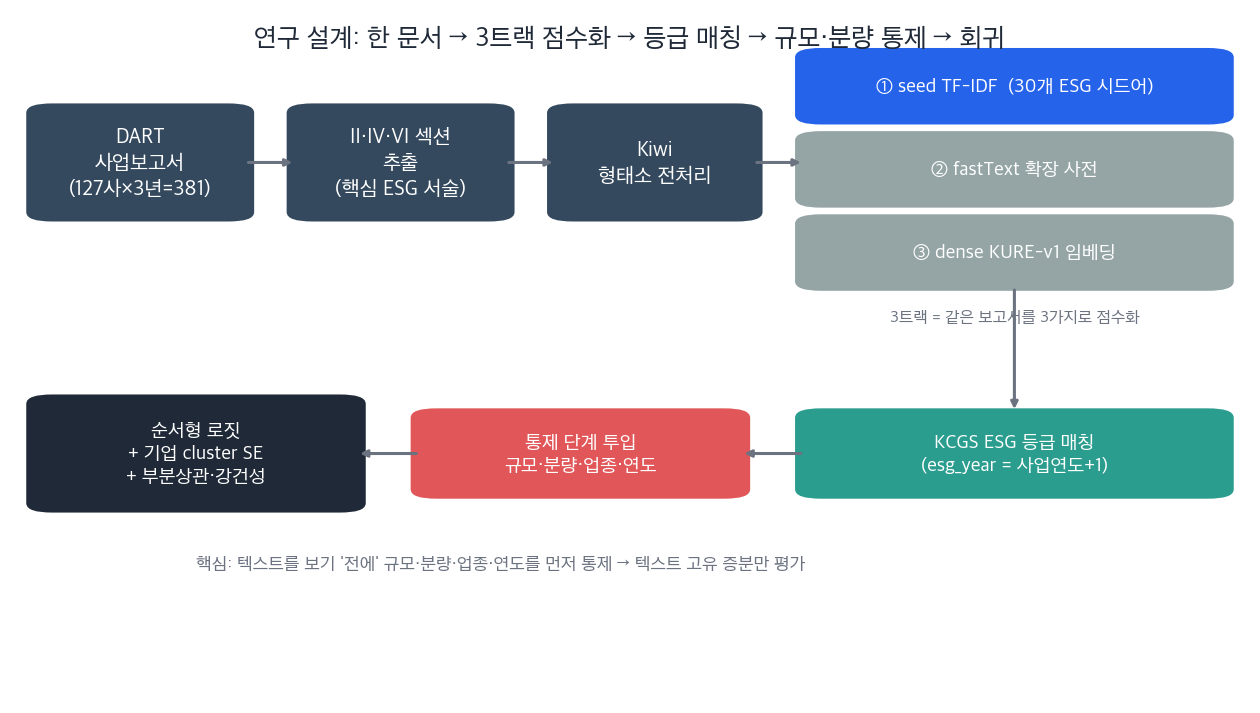

In [2]:
def fig01_design_flow():
    fig, ax = plt.subplots(figsize=(16, 9))
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

    def box(x, y, w, h, text, fc, ec, tc="white", fs=15, bold=True):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6,rounding_size=2.0",
                                    fc=fc, ec=ec, lw=1.6, mutation_aspect=0.6))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
                fontsize=fs, color=tc, fontweight="bold" if bold else "normal", linespacing=1.4)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="-|>", color=P["muted"], lw=2.2))

    # 상단 메인 파이프라인
    box(2, 70, 17, 16, "DART\n사업보고서\n(127사×3년=381)", P["dominant"], P["dominant"], fs=15)
    box(23, 70, 17, 16, "II·IV·VI 섹션\n추출\n(핵심 ESG 서술)", P["dominant"], P["dominant"], fs=15)
    box(44, 70, 16, 16, "Kiwi\n형태소 전처리", P["dominant"], P["dominant"], fs=15)
    arrow(19, 78, 23, 78); arrow(40, 78, 44, 78); arrow(60, 78, 64, 78)

    # 3트랙 분기 (중앙)
    box(64, 84, 34, 10, "① seed TF-IDF  (30개 ESG 시드어)", P["signal"], P["signal"], fs=14)
    box(64, 72, 34, 10, "② fastText 확장 사전", P["control"], P["control"], fs=14)
    box(64, 60, 34, 10, "③ dense KURE-v1 임베딩", P["control"], P["control"], fs=14)
    ax.text(81, 55.5, "3트랙 = 같은 보고서를 3가지로 점수화", ha="center", va="center",
            fontsize=12, color=P["muted"], style="italic")

    # 하단: 등급 매칭 → 통제 → 회귀
    box(64, 30, 34, 12, "KCGS ESG 등급 매칭\n(esg_year = 사업연도+1)", P["driver"], P["driver"], fs=14)
    box(33, 30, 26, 12, "통제 단계 투입\n규모·분량·업종·연도", P["neg"], P["neg"], fs=14)
    box(2, 28, 26, 16, "순서형 로짓\n+ 기업 cluster SE\n+ 부분상관·강건성", P["ink"], P["ink"], fs=14)

    arrow(81, 60, 81, 42)            # 3트랙 → 등급매칭
    arrow(64, 36, 59, 36)            # 등급 → 통제
    arrow(33, 36, 28, 36)            # 통제 → 회귀

    ax.text(50, 96, "연구 설계: 한 문서 → 3트랙 점수화 → 등급 매칭 → 규모·분량 통제 → 회귀",
            ha="center", va="center", fontsize=19, color=P["ink"], fontweight="bold")
    ax.text(15, 20, "핵심: 텍스트를 보기 '전에' 규모·분량·업종·연도를 먼저 통제 → 텍스트 고유 증분만 평가",
            ha="left", va="center", fontsize=13, color=P["muted"])
    save_fig(fig, "fig01_design_flow")

fig01_design_flow()   # inline 표시 + png/pdf 저장

### 슬5 — 규모가 먼저(43%)
`fig02_size_first` · 단일 막대 + 43% 대형 주석. 화살표 주석은 `ax.annotate(... xytext=...)` 좌표로 이동.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig02_size_first.png·.pdf` 저장**.

saved fig02_size_first → /Users/home1/esg-dart-project/reports/presentation_figures


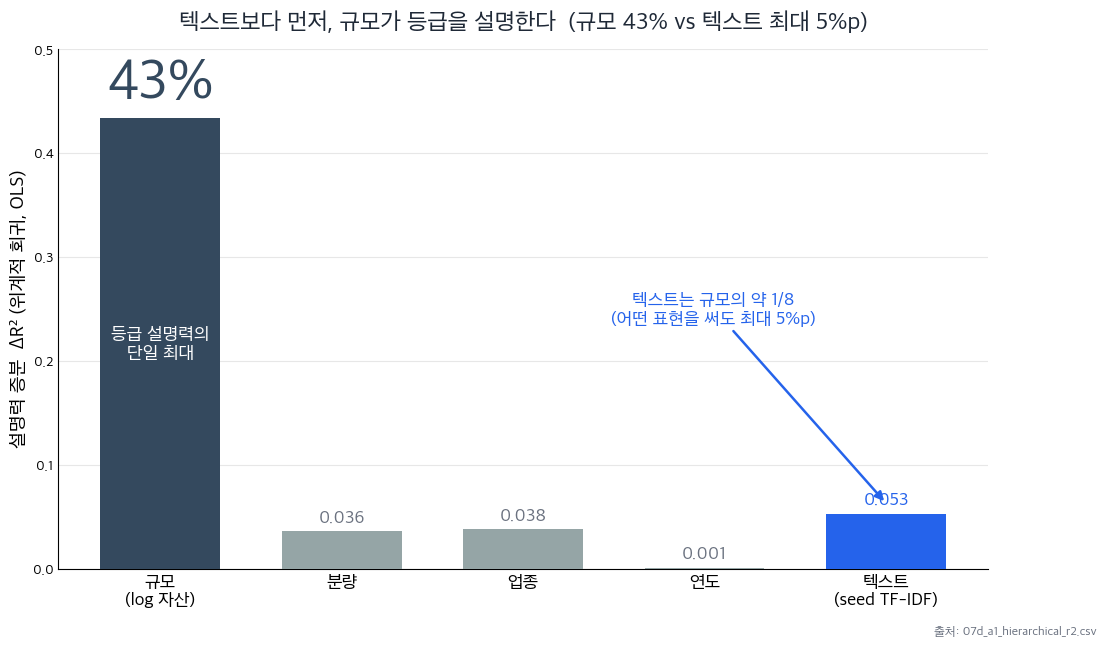

In [3]:
def fig02_size_first():
    t = pd.read_csv(f"{DP}/07d_a1_hierarchical_r2.csv")
    pick = {
        "규모\n(log 자산)": float(t.loc[t.block == "+규모", "ols_dr2"].iloc[0]),
        "분량": float(t.loc[t.block == "+분량", "ols_dr2"].iloc[0]),
        "업종": float(t.loc[t.block == "+산업", "ols_dr2"].iloc[0]),
        "연도": float(t.loc[t.block == "+연도", "ols_dr2"].iloc[0]),
        "텍스트\n(seed TF-IDF)": float(t.loc[t.block == "+텍스트:① seed TF-IDF", "ols_dr2"].iloc[0]),
    }
    labels = list(pick); vals = list(pick.values())
    colors = [P["dominant"], P["control"], P["control"], P["control"], P["signal"]]

    fig, ax = plt.subplots(figsize=BODY)
    bars = ax.bar(labels, vals, color=colors, width=0.66, zorder=3)
    ax.set_ylim(0, 0.50)
    ax.set_ylabel("설명력 증분  ΔR² (위계적 회귀, OLS)", fontsize=14)
    ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
    _despine(ax)
    ax.tick_params(axis="x", labelsize=13)

    # 규모 위 초대형 43%
    ax.text(0, vals[0] + 0.012, "43%", ha="center", va="bottom",
            fontsize=40, fontweight="bold", color=P["dominant"])
    ax.text(0, vals[0] / 2, "등급 설명력의\n단일 최대", ha="center", va="center",
            fontsize=13, color="white", fontweight="bold")
    # 나머지 막대 값
    for i, b in enumerate(bars):
        if i == 0:
            continue
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.006,
                f"{vals[i]:.3f}", ha="center", va="bottom", fontsize=13,
                color=P["signal"] if i == 4 else P["muted"],
                fontweight="bold" if i == 4 else "normal")
    # 텍스트=규모의 1/8 주석
    ax.annotate("텍스트는 규모의 약 1/8\n(어떤 표현을 써도 최대 5%p)",
                xy=(4, vals[4] + 0.01), xytext=(3.05, 0.235),
                fontsize=13, color=P["signal"], ha="center", fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color=P["signal"], lw=1.8))

    ax.set_title("텍스트보다 먼저, 규모가 등급을 설명한다  (규모 43% vs 텍스트 최대 5%p)",
                 fontsize=17, fontweight="bold", color=P["ink"], pad=14)
    fig.text(0.99, 0.01, "출처: 07d_a1_hierarchical_r2.csv", ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig02_size_first")

fig02_size_first()   # inline 표시 + png/pdf 저장

### A4 — 분량 착시 해체
`fig03_length_myth` · before/after 막대. (현재 deck 본문 미사용, A4 또는 슬5 보조용.)

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig03_length_myth.png·.pdf` 저장**.

saved fig03_length_myth → /Users/home1/esg-dart-project/reports/presentation_figures


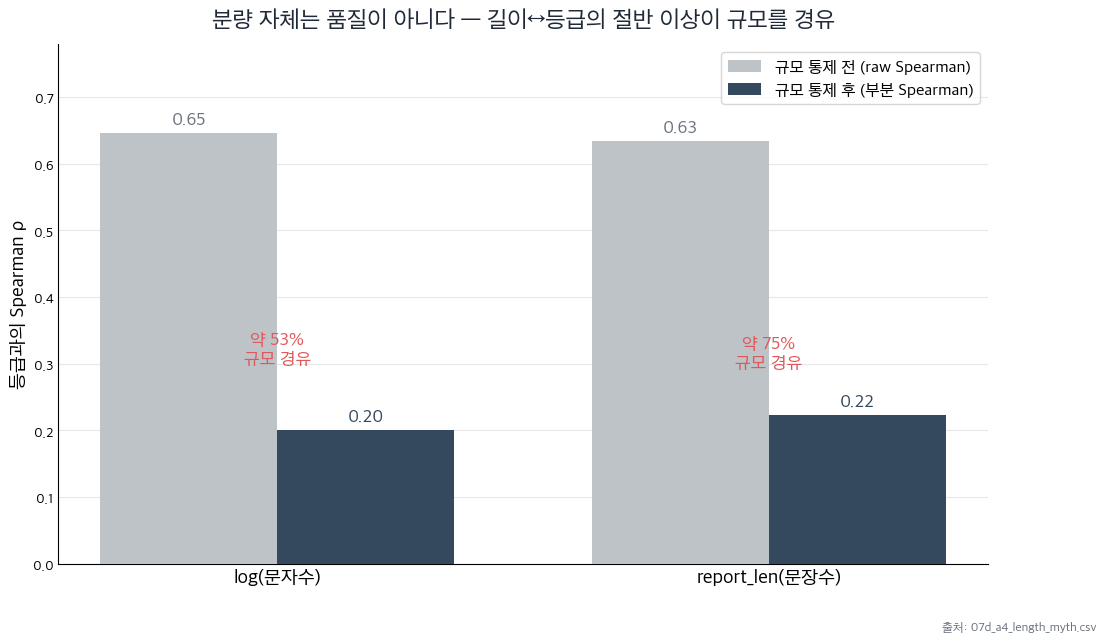

In [4]:
def fig03_length_myth():
    t = pd.read_csv(f"{DP}/07d_a4_length_myth.csv")
    labels = ["log(문자수)", "report_len(문장수)"]
    raw = t["spearman_raw"].tolist()
    partial = t["partial_spearman_ctrl_size"].tolist()
    pct = (t["pct_via_size"] * 100).tolist()

    fig, ax = plt.subplots(figsize=BODY)
    x = np.arange(2); bw = 0.36
    ax.bar(x - bw / 2, raw, bw, color=P["text_weak"], zorder=3, label="규모 통제 전 (raw Spearman)")
    ax.bar(x + bw / 2, partial, bw, color=P["dominant"], zorder=3, label="규모 통제 후 (부분 Spearman)")
    for xi, (r, pa, pc) in enumerate(zip(raw, partial, pct)):
        ax.text(xi - bw / 2, r + 0.012, f"{r:.2f}", ha="center", fontsize=13, color=P["muted"])
        ax.text(xi + bw / 2, pa + 0.012, f"{pa:.2f}", ha="center", fontsize=13, fontweight="bold", color=P["dominant"])
        ax.annotate(f"약 {pc:.0f}%\n규모 경유", xy=(xi, max(r, pa) / 2), ha="center", va="center",
                    fontsize=13, color=P["neg"], fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=14)
    ax.set_ylabel("등급과의 Spearman ρ", fontsize=14)
    ax.set_ylim(0, 0.78)
    ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True); _despine(ax)
    ax.legend(fontsize=12, loc="upper right")
    ax.set_title("분량 자체는 품질이 아니다 — 길이↔등급의 절반 이상이 규모를 경유",
                 fontsize=17, fontweight="bold", color=P["ink"], pad=12)
    fig.text(0.99, 0.01, "출처: 07d_a4_length_myth.csv", ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig03_length_myth")

fig03_length_myth()   # inline 표시 + png/pdf 저장

### 슬6 — 생존 매트릭스(메타발견)
`fig04_survival_matrix` · 4×3 색 매트릭스 + 하단 메타 띠. 셀 크기는 `Rectangle`·`set_xlim/ylim`로.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig04_survival_matrix.png·.pdf` 저장**.

saved fig04_survival_matrix → /Users/home1/esg-dart-project/reports/presentation_figures


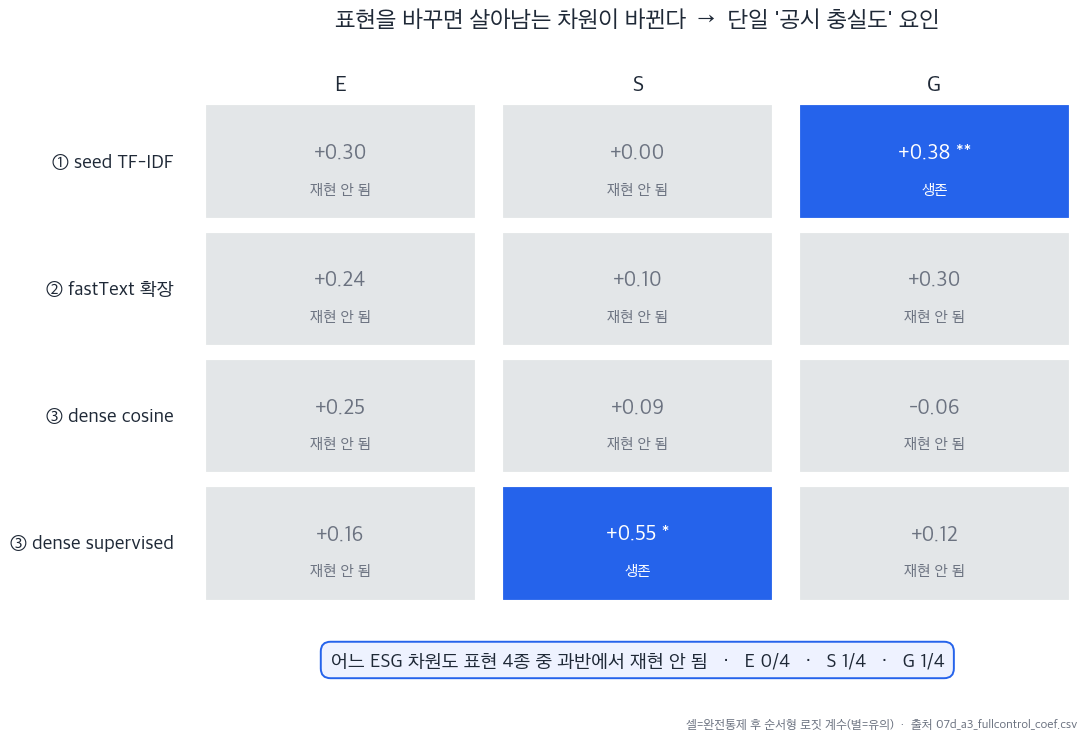

In [5]:
def fig04_survival_matrix():
    c = pd.read_csv(f"{DP}/07d_a3_fullcontrol_coef.csv")
    reprs = ["① seed TF-IDF", "② fastText 확장", "③ dense cosine", "③ dense supervised"]
    dims = ["E", "S", "G"]
    fig, ax = plt.subplots(figsize=(11.5, 6.6))
    ax.set_xlim(0, 3); ax.set_ylim(0, 4); ax.axis("off")

    for ri, rl in enumerate(reprs):
        y = 3 - ri  # top row first
        ax.text(-0.06, y + 0.5, rl, ha="right", va="center", fontsize=14, fontweight="bold", color=P["ink"])
        for di, dl in enumerate(dims):
            row = c[(c.label == rl) & (c.dim == dl)].iloc[0]
            survive = isinstance(row["sig"], str) and row["sig"].strip() in ("*", "**", "***")
            fc = P["signal"] if survive else P["null"]
            tc = "white" if survive else P["muted"]
            ax.add_patch(Rectangle((di + 0.04, y + 0.04), 0.92, 0.92, fc=fc, ec="white", lw=3))
            star = row["sig"].strip() if isinstance(row["sig"], str) else ""
            txt = f"{row['coef']:+.2f}{(' ' + star) if star else ''}"
            ax.text(di + 0.5, y + 0.58, txt, ha="center", va="center",
                    fontsize=15, fontweight="bold" if survive else "normal", color=tc)
            ax.text(di + 0.5, y + 0.28, "생존" if survive else "재현 안 됨",
                    ha="center", va="center", fontsize=11, color=tc)
    for di, dl in enumerate(dims):
        ax.text(di + 0.5, 4.12, dl, ha="center", va="center", fontsize=16, fontweight="bold", color=P["ink"])

    band = "어느 ESG 차원도 표현 4종 중 과반에서 재현 안 됨   ·   E 0/4   ·   S 1/4   ·   G 1/4"
    ax.text(1.5, -0.42, band, ha="center", va="center", fontsize=14, fontweight="bold",
            color=P["ink"], bbox=dict(boxstyle="round,pad=0.5", fc="#eef2ff", ec=P["signal"], lw=1.4))
    ax.text(1.5, 4.62, "표현을 바꾸면 살아남는 차원이 바뀐다  →  단일 '공시 충실도' 요인",
            ha="center", va="center", fontsize=17, fontweight="bold", color=P["ink"])
    ax.text(2.98, -0.92, "셀=완전통제 후 순서형 로짓 계수(별=유의)  ·  출처 07d_a3_fullcontrol_coef.csv",
            ha="right", va="center", fontsize=9, color=P["muted"])
    save_fig(fig, "fig04_survival_matrix")

fig04_survival_matrix()   # inline 표시 + png/pdf 저장

### 슬7 — DRIVER vs BOILER
`fig05_driver_boiler` · 좌 단어카드 + 우 막대(외부 G등급=진한색 주인공). 하단 캡션이 잘리면 `fig.text(0.5,-0.02,...)`의 y를 올린다.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig05_driver_boiler.png·.pdf` 저장**.

saved fig05_driver_boiler → /Users/home1/esg-dart-project/reports/presentation_figures


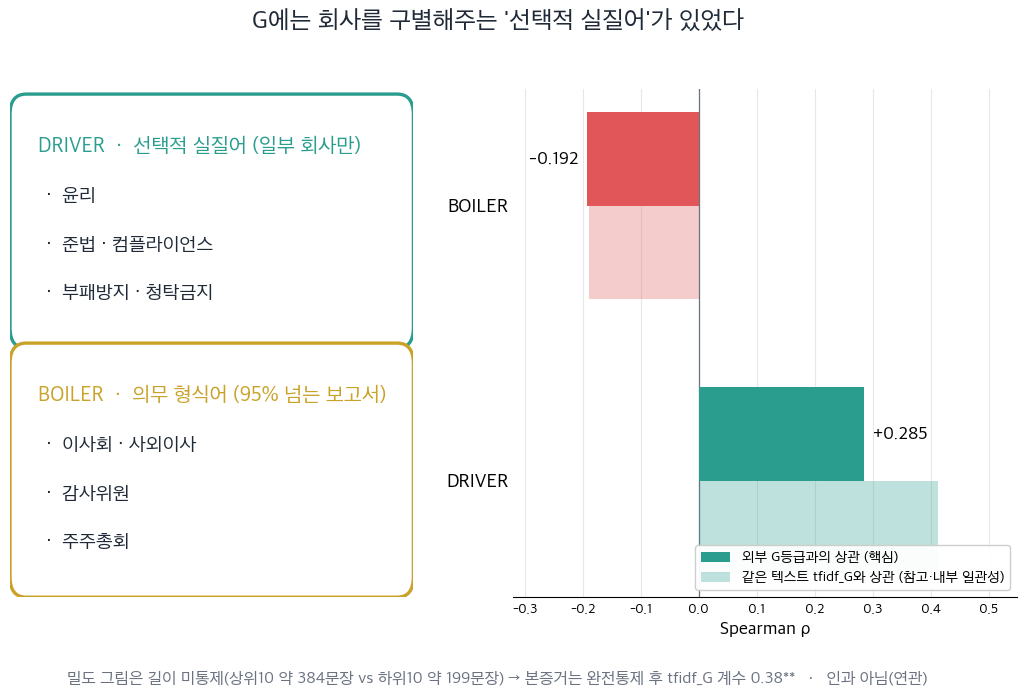

In [6]:
def fig05_driver_boiler():
    kd = pd.read_csv(f"{DP}/08_h2_keyword_density_corr.csv")
    tb = pd.read_csv(f"{DP}/08_h2_top_vs_bottom.csv")

    def get(prefix, col):
        return float(kd.loc[kd.keyword_group.str.startswith(prefix), col].iloc[0])

    drv_g, drv_t = get("DRIVER", "rho_with_g_grade"), get("DRIVER", "rho_with_tfidf_G")
    boi_g, boi_t = get("BOILER", "rho_with_g_grade"), get("BOILER", "rho_with_tfidf_G")
    n_top = int(round(tb.loc[tb.metric.str.startswith("문장"), "top10_mean"].iloc[0]))
    n_bot = int(round(tb.loc[tb.metric.str.startswith("문장"), "bot10_mean"].iloc[0]))

    fig = plt.figure(figsize=(13, 6.6))
    gsax = fig.add_gridspec(1, 2, width_ratios=[1.0, 1.25], wspace=0.22)
    axc = fig.add_subplot(gsax[0]); axc.axis("off"); axc.set_xlim(0, 10); axc.set_ylim(0, 10)

    def card(x, y, w, h, title, words, color):
        axc.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=0.4",
                                     fc="white", ec=color, lw=2.4))
        axc.text(x + 0.4, y + h - 0.7, title, ha="left", va="center", fontsize=15, fontweight="bold", color=color)
        for i, wd in enumerate(words):
            axc.text(x + 0.6, y + h - 1.7 - i * 0.95, f"·  {wd}", ha="left", va="center",
                     fontsize=14, color=P["ink"])

    card(0.3, 5.2, 9.4, 4.4, "DRIVER  ·  선택적 실질어 (일부 회사만)",
         ["윤리", "준법 · 컴플라이언스", "부패방지 · 청탁금지"], P["driver"])
    card(0.3, 0.3, 9.4, 4.4, "BOILER  ·  의무 형식어 (95% 넘는 보고서)",
         ["이사회 · 사외이사", "감사위원", "주주총회"], P["boiler"])

    # 우: 막대 (g등급=주인공 진한색, tfidf_G=참고 옅게)
    axb = fig.add_subplot(gsax[1])
    groups = ["DRIVER", "BOILER"]
    yidx = np.arange(2)
    bw = 0.34
    axb.barh(yidx + bw / 2, [drv_g, boi_g], height=bw, color=[P["driver"], P["neg"]],
             zorder=3, label="외부 G등급과의 상관 (핵심)")
    axb.barh(yidx - bw / 2, [drv_t, boi_t], height=bw, color=[P["driver"], P["neg"]], alpha=0.30,
             zorder=3, label="같은 텍스트 tfidf_G와 상관 (참고·내부 일관성)")
    axb.axvline(0, color=P["muted"], lw=0.9)
    axb.set_yticks(yidx); axb.set_yticklabels(groups, fontsize=14, fontweight="bold")
    axb.set_xlim(-0.32, 0.55)
    axb.set_xlabel("Spearman ρ", fontsize=13)
    for yi, v in zip(yidx + bw / 2, [drv_g, boi_g]):
        axb.text(v + (0.015 if v >= 0 else -0.015), yi, f"{v:+.3f}",
                 va="center", ha="left" if v >= 0 else "right", fontsize=13, fontweight="bold")
    axb.legend(fontsize=10.5, loc="lower right", framealpha=0.95)
    axb.yaxis.grid(False); axb.xaxis.grid(True, alpha=0.3); axb.set_axisbelow(True)
    _despine(axb, keep=("bottom",))

    fig.suptitle("G에는 회사를 구별해주는 '선택적 실질어'가 있었다", fontsize=18, fontweight="bold", color=P["ink"], y=1.0)
    fig.text(0.5, -0.02,
             f"밀도 그림은 길이 미통제(상위10 약 {n_top}문장 vs 하위10 약 {n_bot}문장) → 본증거는 완전통제 후 tfidf_G 계수 0.38**   ·   인과 아님(연관)",
             ha="center", fontsize=12, color=P["muted"])
    save_fig(fig, "fig05_driver_boiler")

fig05_driver_boiler()   # inline 표시 + png/pdf 저장

### 슬8 — TF-IDF vs dense 개념도
`fig06_tfidf_vs_dense` · 개념 다이어그램(수작업 배치). 박스/화살표 좌표 0~100 좌표계.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig06_tfidf_vs_dense.png·.pdf` 저장**.

saved fig06_tfidf_vs_dense → /Users/home1/esg-dart-project/reports/presentation_figures


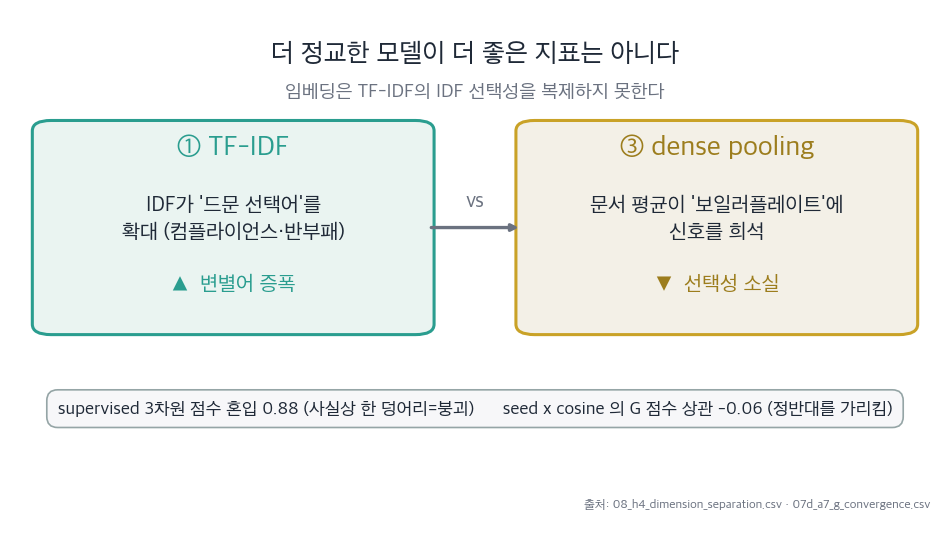

In [7]:
def fig06_tfidf_vs_dense():
    ds = pd.read_csv(f"{DP}/08_h4_dimension_separation.csv")
    gc = pd.read_csv(f"{DP}/07d_a7_g_convergence.csv")

    def off(label):
        return float(ds.loc[ds.repr.str.contains(label), "mean_offdiag"].iloc[0])

    sup_off = off("supervised")
    g_conv = float(gc[(gc.repr_a == "seed_tfidf") & (gc.repr_b == "dense_cos")]["spearman"].iloc[0])

    fig, ax = plt.subplots(figsize=BODY)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

    ax.add_patch(FancyBboxPatch((3, 38), 42, 40, boxstyle="round,pad=0.6,rounding_size=2",
                                fc="#eaf4f1", ec=P["driver"], lw=2.2))
    ax.text(24, 72, "① TF-IDF", ha="center", fontsize=20, fontweight="bold", color=P["driver"])
    ax.text(24, 60, "IDF가 '드문 선택어'를\n확대 (컴플라이언스·반부패)", ha="center", va="center",
            fontsize=15, color=P["ink"], linespacing=1.5)
    ax.text(24, 46, "▲  변별어 증폭", ha="center", fontsize=15, fontweight="bold", color=P["driver"])

    ax.add_patch(FancyBboxPatch((55, 38), 42, 40, boxstyle="round,pad=0.6,rounding_size=2",
                                fc="#f3f0e7", ec=P["boiler"], lw=2.2))
    ax.text(76, 72, "③ dense pooling", ha="center", fontsize=20, fontweight="bold", color="#9c7d1d")
    ax.text(76, 60, "문서 평균이 '보일러플레이트'에\n신호를 희석", ha="center", va="center",
            fontsize=15, color=P["ink"], linespacing=1.5)
    ax.text(76, 46, "▼  선택성 소실", ha="center", fontsize=15, fontweight="bold", color="#9c7d1d")

    ax.annotate("", xy=(55, 58), xytext=(45, 58),
                arrowprops=dict(arrowstyle="-|>", color=P["muted"], lw=2.4))
    ax.text(50, 62, "vs", ha="center", fontsize=15, color=P["muted"], fontweight="bold")

    ax.text(50, 90, "더 정교한 모델이 더 좋은 지표는 아니다", ha="center", fontsize=19,
            fontweight="bold", color=P["ink"])
    ax.text(50, 83, "임베딩은 TF-IDF의 IDF 선택성을 복제하지 못한다", ha="center", fontsize=14, color=P["muted"])

    foot = (f"supervised 3차원 점수 혼입 {sup_off:.2f} (사실상 한 덩어리=붕괴)      "
            f"seed x cosine 의 G 점수 상관 {g_conv:+.2f} (정반대를 가리킴)")
    ax.text(50, 22, foot, ha="center", fontsize=13, color=P["ink"],
            bbox=dict(boxstyle="round,pad=0.6", fc="#f7f7f9", ec=P["control"], lw=1.2))
    ax.text(99, 4, "출처: 08_h4_dimension_separation.csv · 07d_a7_g_convergence.csv",
            ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig06_tfidf_vs_dense")

fig06_tfidf_vs_dense()   # inline 표시 + png/pdf 저장

### 슬10 — 공시량 대비 등급 사분면
`fig07_quadrant` · 산점도(색=통제 잔차, `_resid`로 재현). 라벨 중립 유지(과대공시·그린워싱 금지).

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig07_quadrant.png·.pdf` 저장**.

saved fig07_quadrant → /Users/home1/esg-dart-project/reports/presentation_figures


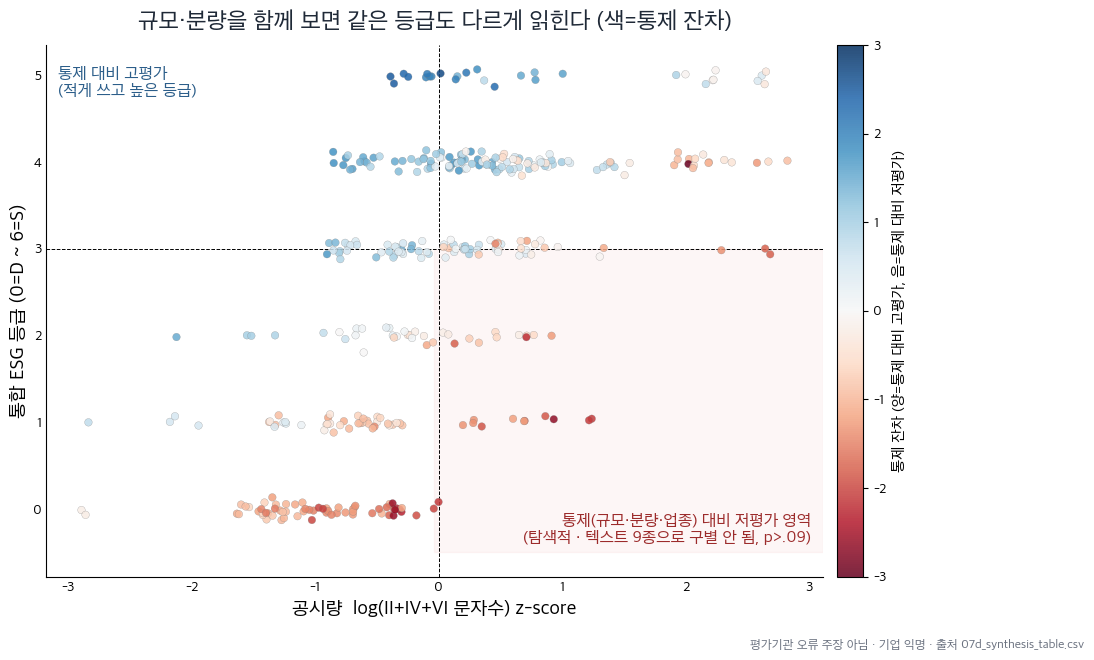

In [8]:
def fig07_quadrant():
    m = pd.read_csv(f"{DP}/07d_synthesis_table.csv")
    Z = m[[SIZE_Z, LEN_Z] + SECTOR_DUMMIES].to_numpy(float)
    m["resid"] = _resid(m[INTEG_GRADE].to_numpy(float), Z)  # OLS 잔차 동일 재현(no new model)
    rng = np.random.default_rng(7)
    yj = m[INTEG_GRADE].to_numpy(float) + rng.normal(0, 0.06, len(m))

    fig, ax = plt.subplots(figsize=(12, 6.9))
    sc = ax.scatter(m["log_core_doc_len_z"], yj, c=m["resid"], cmap="RdBu", vmin=-3, vmax=3,
                    s=30, alpha=0.85, edgecolor="gray", linewidth=0.2, zorder=3)
    ymed = float(m[INTEG_GRADE].median())
    ax.axvline(0, color="k", lw=0.7, ls="--"); ax.axhline(ymed, color="k", lw=0.7, ls="--")

    # 우하단 음영 = 통제 대비 저평가 영역 (중립 라벨)
    ax.axhspan(-0.5, ymed, xmin=0.5, xmax=1.0, color=P["neg"], alpha=0.05, zorder=0)
    ax.text(0.985, 0.06, "통제(규모·분량·업종) 대비 저평가 영역\n(탐색적 · 텍스트 9종으로 구별 안 됨, p>.09)",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=12, color="#9c2b2b")
    ax.text(0.015, 0.96, "통제 대비 고평가\n(적게 쓰고 높은 등급)", transform=ax.transAxes,
            ha="left", va="top", fontsize=12, color="#2c5e8a")

    ax.set_xlabel("공시량  log(II+IV+VI 문자수) z-score", fontsize=14)
    ax.set_ylabel("통합 ESG 등급 (0=D ~ 6=S)", fontsize=14)
    ax.set_title("규모·분량을 함께 보면 같은 등급도 다르게 읽힌다 (색=통제 잔차)",
                 fontsize=17, fontweight="bold", color=P["ink"], pad=12)
    cb = plt.colorbar(sc, ax=ax, pad=0.015)
    cb.set_label("통제 잔차 (양=통제 대비 고평가, 음=통제 대비 저평가)", fontsize=11)
    _despine(ax)
    fig.text(0.99, 0.005, "평가기관 오류 주장 아님 · 기업 익명 · 출처 07d_synthesis_table.csv",
             ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig07_quadrant")

fig07_quadrant()   # inline 표시 + png/pdf 저장

### A5/슬11 — 약신호 forest CI
`fig08_forest_ci` · forest. 우측 CI 라벨이 잘리면 `set_xlim` 상한을 키운다.

> 셀을 재실행하면 **inline 표시 + `reports/presentation_figures/fig08_forest_ci.png·.pdf` 저장**.

saved fig08_forest_ci → /Users/home1/esg-dart-project/reports/presentation_figures


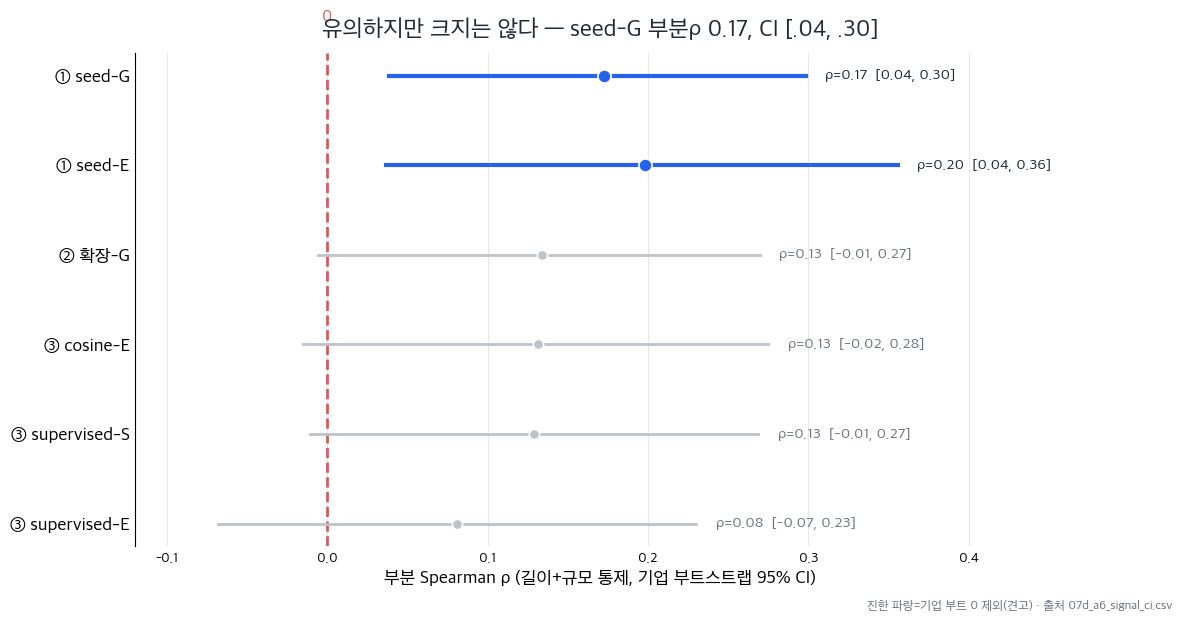

In [9]:
def fig08_forest_ci():
    s = pd.read_csv(f"{DP}/07d_a6_signal_ci.csv")
    s = s.iloc[::-1].reset_index(drop=True)  # seed-G 위로
    fig, ax = plt.subplots(figsize=(12, 6.4))
    for i, r in s.iterrows():
        strong = bool(r["firm_excl0"])
        col = P["signal"] if strong else P["text_weak"]
        ax.plot([r["firm_ci_lo"], r["firm_ci_hi"]], [i, i], color=col, lw=3 if strong else 2, zorder=2)
        ax.scatter(r["obs_partial_rho"], i, color=col, s=90 if strong else 55, zorder=3,
                   edgecolor="white", linewidth=1.2)
        ax.text(r["firm_ci_hi"] + 0.012, i, f"ρ={r['obs_partial_rho']:.2f}  [{r['firm_ci_lo']:.2f}, {r['firm_ci_hi']:.2f}]",
                va="center", fontsize=11, color=P["ink"] if strong else P["muted"],
                fontweight="bold" if strong else "normal")
    ax.axvline(0, color=P["neg"], lw=2.0, ls="--", zorder=1)
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s["signal"], fontsize=13)
    ax.set_xlim(-0.12, 0.46)
    ax.set_xlabel("부분 Spearman ρ (길이+규모 통제, 기업 부트스트랩 95% CI)", fontsize=13)
    ax.set_title("유의하지만 크지는 않다 — seed-G 부분ρ 0.17, CI [.04, .30]",
                 fontsize=17, fontweight="bold", color=P["ink"], pad=12)
    ax.text(0.0, len(s) - 0.4, "0", color=P["neg"], fontsize=12, ha="center", fontweight="bold")
    _despine(ax, keep=("left",))
    ax.xaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
    fig.text(0.99, 0.01, "진한 파랑=기업 부트 0 제외(견고) · 출처 07d_a6_signal_ci.csv",
             ha="right", fontsize=9, color=P["muted"])
    save_fig(fig, "fig08_forest_ci")

fig08_forest_ci()   # inline 표시 + png/pdf 저장

## 9. 일괄 재생성 / 배치
모든 그림을 한 번에(헤드리스) 다시 만들려면 셀 대신 배치 스크립트를 쓴다:

```bash
uv run python analysis/09_presentation_figures.py
```

- 이 노트북과 배치 `.py`의 그림 함수는 **동일 코드**다(이 노트북은 `_build_09_notebook.py`가
  `.py`에서 `getsource`로 가져와 빌드). 함수 본문을 수정했다면 양쪽을 맞춰 두면 좋다.
- 발표 deck(`outputs/발표_15분_marp.md`)은 `../reports/presentation_figures/figNN_*.png`를 참조한다.
- 동반 표: `reports/presentation_figures/README_presentation_figures.md`.